# 01 Explore: ERA5 100 m wind at Pen y Cymoedd

Load the ERA5 site file and sanity-check it before any modelling.

In [1]:
import sys
from pathlib import Path

# Should be the prs env (Python 3.12). If not, pick the "Python (prs)" kernel.
print(sys.executable)
print(sys.version)

# Make src/prs importable from the notebooks folder
sys.path.insert(0, str(Path.cwd().parent / "src"))

C:\Users\admin\anaconda3\envs\prs\python.exe
3.12.14 | packaged by conda-forge | (main, Sep  2 2026, 23:18:20) [MSC v.1944 64 bit (AMD64)]


In [2]:
import numpy as np
import xarray as xr

from prs.data import RAW

ds = xr.open_dataset(RAW / "era5_pyc_100m_1940_2026.nc")
ds

<xarray.Dataset> Size: 61MB
Dimensions:     (valid_time: 760464, latitude: 3, longitude: 3)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6MB 1940-01-01 ... 2026-10-01T23:...
  * latitude    (latitude) float64 24B 51.5 51.75 52.0
  * longitude   (longitude) float64 24B -3.75 -3.5 -3.25
Data variables:
    u100        (valid_time, latitude, longitude) float32 27MB ...
    v100        (valid_time, latitude, longitude) float32 27MB ...
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2024-09-02T04:48 GRIB to CDM+CF via cfgrib-0.9.1...
    institution:             European Centre for Medium-Range Weather Forecasts

In [3]:
# Wind speed from the u (eastward) and v (northward) components
ws100 = np.hypot(ds["u100"], ds["v100"]).rename("ws100")
ws100.attrs = {"long_name": "100 m wind speed", "units": "m s-1"}
ws100

<xarray.DataArray 'ws100' (valid_time: 760464, latitude: 3, longitude: 3)> Size: 27MB
array([[[6.9141855, 5.8619056, 4.885718 ],
        [5.420206 , 4.5508456, 3.5851927],
        [4.538513 , 3.6439104, 3.1503139]],

       [[7.351848 , 6.15784  , 5.1408906],
        [5.764038 , 4.82482  , 3.8189487],
        [4.8105845, 3.810905 , 3.2837987]],

       [[7.2952857, 6.1676645, 5.3263454],
        [5.9856777, 5.0646753, 4.212871 ],
        [5.059411 , 4.1556993, 3.6915636]],

       ...,

       [[6.9110937, 6.3862305, 6.124205 ],
        [6.5692377, 6.3450365, 6.0985937],
        [6.561131 , 6.336591 , 6.0933266]],

       [[7.993539 , 7.3742285, 6.964945 ],
        [7.6217804, 7.115298 , 6.7161727],
        [7.5550966, 7.0579886, 6.6326613]],

       [[7.960704 , 7.388677 , 7.0133123],
        [7.8401847, 7.282768 , 6.910236 ],
        [7.962307 , 7.41068  , 6.9792366]]],
      shape=(760464, 3, 3), dtype=float32)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6MB 1940-01-01 ... 2026-10-01T23:...
  * latitude    (latitude) float64 24B 51.5 51.75 52.0
  * longitude   (longitude) float64 24B -3.75 -3.5 -3.25
Attributes:
    long_name:  100 m wind speed
    units:      m s-1

In [4]:
# Sanity checks: 3x3 grid, hourly with no gaps, no missing values
print("grid:", ds.sizes["latitude"], "x", ds.sizes["longitude"])
print("period:", ds["valid_time"].values[0], "to", ds["valid_time"].values[-1])

steps = np.diff(ds["valid_time"].values)
print("time steps that are not 1 hour:", int((steps != np.timedelta64(1, "h")).sum()))
print("missing values:", int(ws100.isnull().sum()))

grid: 3 x 3
period: 1940-01-01T00:00:00.000000000 to 2026-10-01T23:00:00.000000000
time steps that are not 1 hour: 0
missing values: 0


In [5]:
# Mean wind speed at each grid point (expect roughly 7-9 m/s)
ws100.mean("valid_time").to_pandas().round(2)

longitude,-3.75,-3.50,-3.25
latitude,,,
51.50,7.68,7.34,7.10
51.75,6.82,6.70,6.49
52.00,6.60,6.54,6.44


In [6]:
# Mean by calendar month, averaged over the 9 points (expect winter windier than summer)
ws100.mean(["latitude", "longitude"]).groupby("valid_time.month").mean().to_pandas().round(2)

month
1     8.03
2     7.78
3     7.23
4     6.57
5     6.16
6     5.85
7     5.77
8     5.92
9     6.48
10    7.10
11    7.46
12    8.01
Name: ws100, dtype: float32

## Long-term context

Annual mean wind at the site since 1940. Pre-1979 ERA5 assimilates far fewer
observations, so that part is shown only for context. Models are calibrated
on 1991-2025.

Text(0.0, 1.0, 'Pen y Cymoedd: ERA5 annual mean wind, 1940-2025')

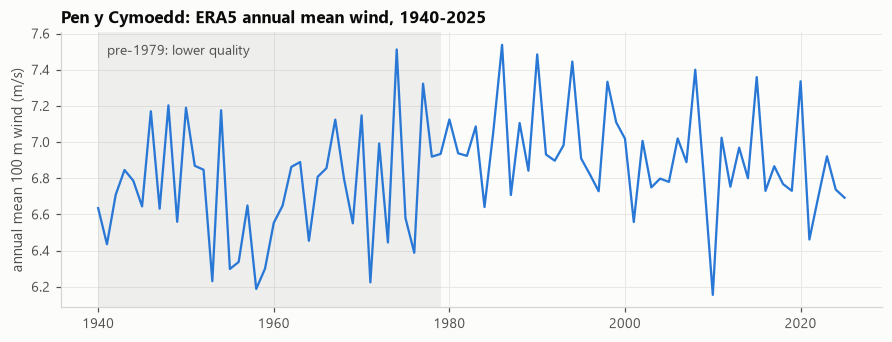

In [7]:
from prs.plotting import fig, BLUE, GREY
site = ws100.interp(latitude=51.71, longitude=-3.56).to_series()
annual = site[:"2025"].groupby(site[:"2025"].index.year).mean()
f, ax = fig(figsize=(8, 3))
ax.plot(annual.index, annual.values, color=BLUE, lw=1.5)
ax.axvspan(1940, 1979, color=GREY, alpha=0.12, lw=0)
ax.text(1941, annual.max(), "pre-1979: lower quality", fontsize=9, color="#52514e", va="top")
ax.set_ylabel("annual mean 100 m wind (m/s)")
ax.set_title("Pen y Cymoedd: ERA5 annual mean wind, 1940-2025")

**Findings.** 3x3 grid, hourly, no gaps or missing values. The grid points
average roughly 6.5-7.5 m/s (slightly below the 7-9 m/s guess: ERA5 smooths
the ridges the turbines sit on, which the power-curve bias correction in
notebook 02 deals with). Winter months are about 2 m/s windier than summer (8.0 vs 5.8 m/s).
Year-to-year means vary by about +/-0.3 m/s, which matters for a 10-year contract.